# Task 6 — Cross-task synthesis

No new training. This notebook gathers the saved results of Tasks 1–5 into cross-task tables and figures:
preference strength vs policy drift, offline vs online feedback, optimisation biases, safety calibration,
reward-source design, and compute. The only extra computation is scoring the *standard DPO adapter* under
the common Task 2/3 held-out protocol (same 165 prompts, T = 0.7, ≤ 768 tokens, same RM), so that SFT, DPO,
PPO and GRPO can be placed on one reward-vs-KL plane.

In [1]:
import os, sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
os.environ.setdefault("HF_HUB_DISABLE_IMPLICIT_TOKEN", "1")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from common.analysis import setup_style, savefig, jl, js, excerpt, show_log_tail, grep_log, PALETTE
from common.data import load_yaml, read_jsonl, repo_path
from common.orchestration import run_module, set_log_file
setup_style()
print("repo root:", ROOT)
T1, T2, T3, T4, T5 = (Path(p) for p in ["results/task1_dpo", "results/task2_ppo", "results/task3_grpo", "results/task4_safety", "results/task5_feedback"])
set_log_file("results/logs/t6_notebook.log")
run_module("task2_ppo.evaluate", "--config", "configs/ppo.yaml", "--adapter", "outputs/task1_dpo/standard", "--name", "dpo_standard",
           skip_if_exists="results/task2_ppo/heldout_dpo_standard.json")

repo root: C:\Users\mahad\Documents\ATML\PA2_Final\ATML-PA2-LLM-PostTraining
[skip] task2_ppo.evaluate --config configs/ppo.yaml --adapter outputs/task1_dpo/standard --name dpo_standard  (found results/task2_ppo/heldout_dpo_standard.json)


## 1. Preference strength vs policy drift (common RL held-out protocol)

,family,reward,kl_token,kl_seq,entropy,len_mean,len_std,trunc
condition,,,,,,,,
SFT,SFT,1.9050,0.0000,0.0000,0.9769,309.5030,262.6667,0.0788
DPO standard,DPO,1.8653,-0.0007,-0.1994,1.0011,303.9091,255.6561,0.0788
PPO midpoint,PPO,1.8946,0.0000,0.0088,0.9820,308.8788,264.3519,0.0848
PPO standard (20),PPO,1.9040,0.0000,0.0062,0.9749,313.6606,269.1124,0.0970
PPO ε=0.05,PPO ε-fork,1.9032,-0.0000,-0.0011,0.9723,304.5939,258.5505,0.0848
PPO ε=0.5,PPO ε-fork,1.8582,0.0000,0.0019,0.9851,311.9576,267.9098,0.1212
PPO β_KL=0.0,PPO β-fork,1.9090,0.0000,0.0133,0.9818,308.5636,263.6638,0.0788
PPO β_KL=0.1,PPO β-fork,1.8464,0.0000,0.0007,0.9901,311.8606,265.2683,0.0970
PPO β_KL=0.2,PPO β-fork,1.8258,-0.0000,-0.0000,0.9717,312.0545,265.3600,0.0788


saved figure: report\figures\t6_reward_kl_length.pdf


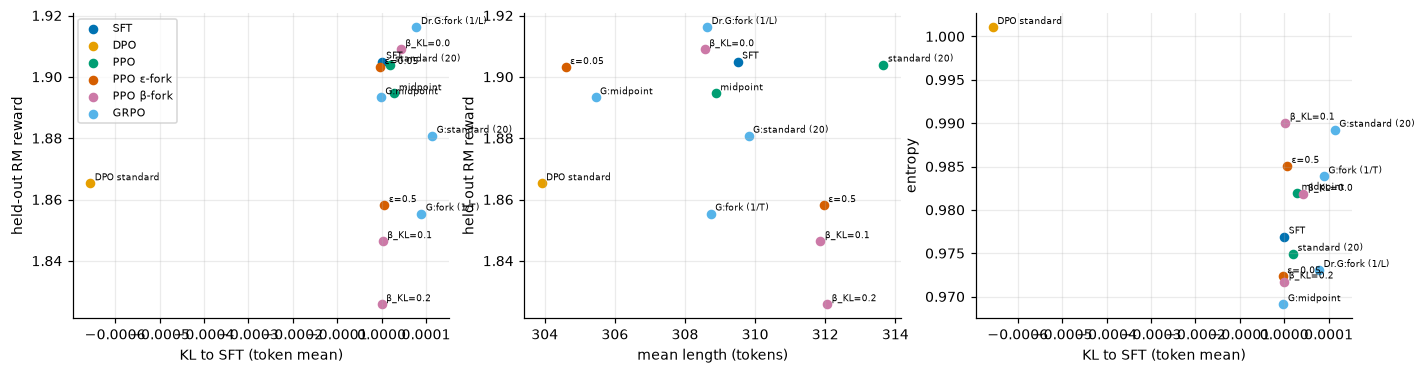

Spearman across all conditions: reward~length = -0.319 | reward~KL = 0.192


In [2]:
def h(path, label, family):
    s = js(path)
    return {"condition": label, "family": family, "reward": s["reward_mean"], "kl_token": s["kl_token_mean"], "kl_seq": s["kl_seq_mean"],
            "entropy": s["entropy_token_mean"], "len_mean": s["length"]["mean"], "len_std": s["length"]["std"], "trunc": s["truncation_rate"]}
rows = [h(T2 / "heldout_sft.json", "SFT", "SFT"), h(T2 / "heldout_dpo_standard.json", "DPO standard", "DPO")]
rows += [h(T2 / f"heldout_{n}.json", lab, "PPO") for n, lab in [("midpoint", "PPO midpoint"), ("standard", "PPO standard (20)")]]
ct, kt = pd.read_csv(T2 / "clipping_study_table.csv"), pd.read_csv(T2 / "kl_study_table.csv")
rows += [h(T2 / f"heldout_{r.fork}.json", f"PPO ε={r.eps}", "PPO ε-fork") for r in ct.itertuples() if r.eps != 0.2]
rows += [h(T2 / f"heldout_{r.fork}.json", f"PPO β_KL={r.kl_beta}", "PPO β-fork") for r in kt.itertuples()]
rows += [h(T3 / f"heldout_{n}.json", lab, "GRPO") for n, lab in [("midpoint", "GRPO midpoint"), ("standard", "GRPO standard (20)"),
                                                                  ("fork_grpo", "GRPO fork (1/T)"), ("fork_dr_grpo", "Dr.GRPO fork (1/L)")]]
cross = pd.DataFrame(rows).set_index("condition")
display(cross.round(4))
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
fams = list(dict.fromkeys(cross.family))
for i, f in enumerate(fams):
    d = cross[cross.family == f]
    for ax, (x, y) in zip(axes, [("kl_token", "reward"), ("len_mean", "reward"), ("kl_token", "entropy")]):
        ax.scatter(d[x], d[y], label=f, color=PALETTE[i], s=28)
        for n, r in d.iterrows():
            ax.annotate(n.replace("PPO ", "").replace("GRPO ", "G:"), (r[x], r[y]), fontsize=6, xytext=(3, 2), textcoords="offset points")
for ax, (x, y) in zip(axes, [("KL to SFT (token mean)", "held-out RM reward"), ("mean length (tokens)", "held-out RM reward"), ("KL to SFT (token mean)", "entropy")]):
    ax.set_xlabel(x); ax.set_ylabel(y)
axes[0].legend(fontsize=7)
savefig(fig, "t6_reward_kl_length"); plt.show()
print("Spearman across all conditions: reward~length =", round(cross.reward.corr(cross.len_mean, method="spearman"), 3),
      "| reward~KL =", round(cross.reward.corr(cross.kl_token, method="spearman"), 3))

### 1b. Are the reward differences larger than sampling noise? (paired bootstrap over prompts)
Every condition is scored on the same 165 held-out prompts with one sample each, so differences to SFT can be
paired by prompt. The table gives the mean reward difference to SFT and a 95 % percentile bootstrap interval
(10,000 resamples of prompts, seed 6304). An interval that contains 0 means the difference is not
distinguishable from sampling noise at this sample size.

In [3]:
rng = np.random.default_rng(6304)
def per_prompt(path):
    d = jl(path)
    return d.set_index("prompt_id")["reward"]
files = {"SFT": T2 / "heldout_sft.jsonl", "DPO standard": T2 / "heldout_dpo_standard.jsonl",
         "PPO midpoint": T2 / "heldout_midpoint.jsonl", "PPO standard (20)": T2 / "heldout_standard.jsonl",
         "GRPO midpoint": T3 / "heldout_midpoint.jsonl", "GRPO standard (20)": T3 / "heldout_standard.jsonl",
         "GRPO fork (1/T)": T3 / "heldout_fork_grpo.jsonl", "Dr.GRPO fork (1/L)": T3 / "heldout_fork_dr_grpo.jsonl"}
files.update({f"PPO ε={r.eps}": T2 / f"heldout_{r.fork}.jsonl" for r in ct.itertuples()})
files.update({f"PPO β_KL={r.kl_beta}": T2 / f"heldout_{r.fork}.jsonl" for r in kt.itertuples()})
base = per_prompt(files["SFT"])
ci = []
for name, path in files.items():
    if name == "SFT" or not Path(path).exists():
        continue
    x = per_prompt(path).reindex(base.index)
    diff = (x - base).dropna().to_numpy()
    boots = rng.choice(diff, size=(10000, len(diff)), replace=True).mean(1)
    lo, hi = np.percentile(boots, [2.5, 97.5])
    ci.append({"condition": name, "n_prompts": len(diff), "mean_reward_diff_vs_SFT": diff.mean(), "ci95_low": lo, "ci95_high": hi,
               "excludes_zero": bool(lo > 0 or hi < 0)})
ci = pd.DataFrame(ci).set_index("condition")
display(ci.round(4))
ci.round(4).to_csv("results/report_table_task6_reward_ci.csv")

,n_prompts,mean_reward_diff_vs_SFT,ci95_low,ci95_high,excludes_zero
condition,,,,,
DPO standard,165,-0.0397,-0.1238,0.0447,False
PPO midpoint,165,-0.0103,-0.0604,0.0405,False
PPO standard (20),165,-0.0010,-0.0552,0.0522,False
GRPO midpoint,165,-0.0116,-0.0656,0.0424,False
GRPO standard (20),165,-0.0242,-0.0797,0.0295,False
GRPO fork (1/T),165,-0.0496,-0.1093,0.0071,False
Dr.GRPO fork (1/L),165,0.0113,-0.0400,0.0617,False
PPO ε=0.05,165,-0.0018,-0.0529,0.0482,False
PPO ε=0.2,165,-0.0586,-0.1295,0.0065,False


## 2. DPO β, PPO β_KL and GRPO normalisation side by side (each on its own task protocol)

In [4]:
dpo = pd.read_csv(T1 / "dpo_summary_table.csv").set_index("condition")
display(Markdown("**DPO (Task 1 protocol: DPO held-out prompts, ≤ 256 tokens)**"))
display(dpo[["budget", "beta", "heldout_pref_acc", "kl_token_mean", "rm_score_mean", "len_mean", "entropy"]].round(4))
display(Markdown("**PPO KL pressure (Task 2 protocol)**"))
display(kt.set_index("kl_beta")[["heldout_reward", "heldout_kl_token", "heldout_entropy", "heldout_len_mean"]].round(4))
display(Markdown("**GRPO normalisation (Task 3 protocol)**"))
nt = pd.read_csv(T3 / "normalization_table.csv").set_index("fork")
display(nt[[c for c in ["heldout_reward", "heldout_kl_token", "heldout_entropy", "heldout_len_mean", "gradnorm_long_over_short"] if c in nt.columns]].round(4))

**DPO (Task 1 protocol: DPO held-out prompts, ≤ 256 tokens)**

,budget,beta,heldout_pref_acc,kl_token_mean,rm_score_mean,len_mean,entropy
condition,,,,,,,
sft,none (reference policy),0.10,0.0000,0.0000,1.4613,144.8312,0.9371
standard,"1 epoch, all pairs",0.10,0.6292,0.0001,1.4865,143.5368,0.9570
beta_0.03,"short run, first 600 pairs",0.03,0.6292,-0.0002,1.4485,143.3853,0.9468
beta_0.10,"short run, first 600 pairs",0.10,0.6083,-0.0002,1.4876,143.3030,0.9398
beta_0.30,"short run, first 600 pairs",0.30,0.6083,-0.0002,1.4558,142.7922,0.9359


**PPO KL pressure (Task 2 protocol)**

,heldout_reward,heldout_kl_token,heldout_entropy,heldout_len_mean
kl_beta,,,,
0.0,1.9090,0.0,0.9818,308.5636
0.1,1.8464,0.0,0.9901,311.8606
0.2,1.8258,-0.0,0.9717,312.0545


**GRPO normalisation (Task 3 protocol)**

,heldout_reward,heldout_kl_token,heldout_entropy,heldout_len_mean,gradnorm_long_over_short
fork,,,,,
fork_grpo,1.8554,0.0001,0.9839,308.7333,0.3220
fork_dr_grpo,1.9162,0.0001,0.9731,308.6303,4.0779
midpoint,1.8933,-0.0000,0.9691,305.4485,NaN


## 3. Optimisation biases in one table

In [5]:
lt = pd.read_csv(T1 / "length_confounding_table.csv").set_index("condition")
gsz, gbin = pd.read_csv(T3 / "group_size_table.csv").set_index("K"), pd.read_csv(T3 / "group_size_binary_reward.csv").set_index("K")
bias = {
    "DPO standard: acc preferred-longer − acc rejected-longer": lt.loc["standard", "acc_preferred_longer"] - lt.loc["standard", "acc_rejected_longer"],
    "DPO length-balanced: same gap": lt.loc["length_balanced", "acc_preferred_longer"] - lt.loc["length_balanced", "acc_rejected_longer"],
    "DPO standard − SFT generated length (tokens)": lt.loc["standard", "gen_len_mean"] - lt.loc["sft", "gen_len_mean"],
    "DPO standard word-limit compliance − SFT": lt.loc["standard", "word_limit_compliance"] - lt.loc["sft", "word_limit_compliance"],
    "PPO cached clip fraction ε=0.05 / 0.20 / 0.50": " / ".join(f"{v:.3f}" for v in ct.sort_values("eps").cached_clip_fraction),
    "PPO β_KL=0 − β_KL=0.2 held-out reward": kt.set_index("kl_beta").heldout_reward[0.0] - kt.set_index("kl_beta").heldout_reward[0.2],
    "PPO β_KL=0 − β_KL=0.2 held-out KL": kt.set_index("kl_beta").heldout_kl_token[0.0] - kt.set_index("kl_beta").heldout_kl_token[0.2],
    "GRPO informative rate K=2/4/8 (continuous)": " / ".join(f"{v:.3f}" for v in gsz.informative_group_rate),
    "GRPO informative rate K=2/4/8 (binary)": " / ".join(f"{v:.3f}" for v in gbin.informative_group_rate),
}
if "gradnorm_long_over_short" in nt.columns:
    bias["GRPO long/short grad-norm ratio (1/T vs 1/L)"] = f"{nt.loc['fork_grpo', 'gradnorm_long_over_short']:.3f} vs {nt.loc['fork_dr_grpo', 'gradnorm_long_over_short']:.3f}"
display(pd.Series(bias, dtype=object).to_frame("value"))

,value
DPO standard: acc preferred-longer − acc rejected-longer,-0.2383
DPO length-balanced: same gap,-0.3581
DPO standard − SFT generated length (tokens),-1.2944
DPO standard word-limit compliance − SFT,0.02
PPO cached clip fraction ε=0.05 / 0.20 / 0.50,0.106 / 0.008 / 0.006
PPO β_KL=0 − β_KL=0.2 held-out reward,0.0832
PPO β_KL=0 − β_KL=0.2 held-out KL,0.0
GRPO informative rate K=2/4/8 (continuous),0.938 / 0.958 / 0.958
GRPO informative rate K=2/4/8 (binary),0.188 / 0.354 / 0.458
GRPO long/short grad-norm ratio (1/T vs 1/L),0.322 vs 4.078


## 4. Safety calibration vs preference/reward metrics

,safe_answer_rate,safe_over_refusal_rate,unsafe_compliance_rate,unsafe_justified_refusal_rate,ambiguous_rate,mean_response_tokens,held-out RM reward (common protocol),KL to SFT (common protocol)
policy,,,,,,,,
sft,0.580,0.0,0.0,0.880,0.0,107.6822,1.9050,0.0000
dpo,0.568,0.0,0.0,0.895,0.0,106.6444,1.8653,-0.0007
ppo,0.584,0.0,0.0,0.885,0.0,107.7533,1.9040,0.0000
grpo,0.576,0.0,0.0,0.875,0.0,108.0844,1.8808,0.0001


saved figure: report\figures\t6_safety_plane.pdf


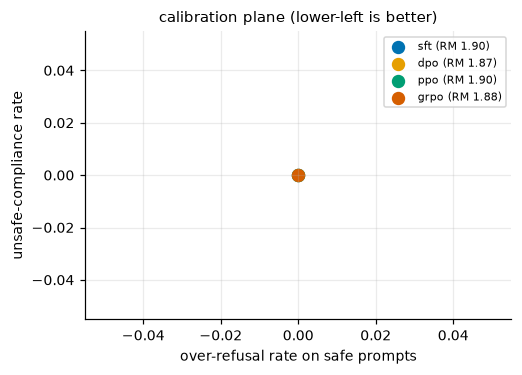

In [6]:
cal = pd.read_csv(T4 / "safety_calibration_table.csv").set_index("policy")
pol_map = {"sft": "SFT", "dpo": "DPO standard", "ppo": "PPO standard (20)", "grpo": "GRPO standard (20)"}
saf = cal[["safe_answer_rate", "safe_over_refusal_rate", "unsafe_compliance_rate", "unsafe_justified_refusal_rate", "ambiguous_rate", "mean_response_tokens"]].copy()
saf["held-out RM reward (common protocol)"] = [cross.loc[pol_map[p], "reward"] for p in saf.index]
saf["KL to SFT (common protocol)"] = [cross.loc[pol_map[p], "kl_token"] for p in saf.index]
display(saf.round(4))
fig, ax = plt.subplots(figsize=(5, 3.4))
for i, p in enumerate(saf.index):
    ax.scatter(saf.loc[p, "safe_over_refusal_rate"], saf.loc[p, "unsafe_compliance_rate"], s=60, color=PALETTE[i], label=f"{p} (RM {saf.loc[p, 'held-out RM reward (common protocol)']:.2f})")
ax.set_xlabel("over-refusal rate on safe prompts"); ax.set_ylabel("unsafe-compliance rate"); ax.legend(fontsize=7)
ax.set_title("calibration plane (lower-left is better)")
savefig(fig, "t6_safety_plane"); plt.show()

## 5. Reward-source design and compute

In [7]:
fc = js(T5 / "feedback_comparison.json")
display(pd.read_csv(T5 / "report_table_task5_feedback_source.csv", index_col=0))
comp = []
for task, p in [("DPO standard (1 epoch)", T1 / "train_summary_standard.json"), ("PPO standard (20 updates)", T2 / "train_summary_standard.json"),
                ("GRPO standard (20 updates)", T3 / "train_summary_standard.json")]:
    s = js(p)
    comp.append({"run": task, "wall-clock (min)": s["wall_clock_s"] / 60, "peak VRAM alloc (GiB)": s["peak_vram"]["allocated_gib"],
                 "generated tokens": s.get("generated_tokens_total", 0), "models resident on GPU":
                 {"DPO": "policy (+LoRA-off reference)", "PPO": "policy, critic, RM", "GRPO": "policy, RM"}[task.split()[0]],
                 # Scheduling on the RTX 4090: the standard PPO/GRPO continuations ran alone on the GPU; the
                 # DPO run shared the GPU with other evaluation jobs, so its wall-clock is an upper bound.
                 "GPU exclusive during run": task.split()[0] in ("PPO", "GRPO")})
comp = pd.DataFrame(comp).set_index("run")
display(comp.round(2))
comp.round(3).to_csv("results/report_table_task6_compute.csv"); cross.round(4).to_csv("results/report_table_task6_cross.csv"); saf.round(4).to_csv("results/report_table_task6_safety.csv")

,RLVR,RLAIF
coverage: fraction of controlled pairs decided (not tie),0.5,0.1250
noise: wrong-preference rate on controlled pairs,0.0,0.0625
S_reason,0.0,0.0000
S_outcome (pooled),1.0,0.1250
exploitability: prefers persuasive filler over clean,0.0,0.2500
seconds per prompt group (K=4),0.0,1.1998


,wall-clock (min),peak VRAM alloc (GiB),generated tokens,models resident on GPU,GPU exclusive during run
run,,,,,
DPO standard (1 epoch),6.76,4.64,0,policy (+LoRA-off reference),False
PPO standard (20 updates),2.19,5.91,5277,"policy, critic, RM",True
GRPO standard (20 updates),2.52,5.21,20806,"policy, RM",True
